# Taller: MLP superficial con TensorFlow-Keras (UCI)

**Autor:** Juan Diego Estupiñán Rincón · Especialización en Inteligencia Artificial

Entrega del taller y recorrido por el repositorio `mlp-uci-biomedical`. La lógica vive en el
paquete `mlp_uci` (probado en `tests/`); aquí solo se ejecuta y se interpreta.

| Punto | Problema | Dataset UCI |
|---|---|---|
| 1 | **Clasificación** (4 clases) | BEED – Bangalore EEG Epilepsy Dataset (id 1134) |
| 2 | **Regresión** | AIDS Clinical Trials Group Study 175 (id 890), objetivo `cd420` (no es el *Adult* dataset) |

Redes **MLP superficiales** (1 o 2 capas ocultas), con **entrenamiento, validación y prueba
disjuntos**: la prueba solo se usa al final. Se prueban **3 optimizadores** y **3 arquitecturas**.

In [7]:
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

from mlp_uci import data as D
from mlp_uci.eda import run_eda_actg175
from mlp_uci.experiments import RunConfig, run_classification, run_regression

BEED_PATH = r"D:\2026\EEG\mlp-uci-biomedical\data\raw\BEED_Data.csv"
ACTG_PATH = r"D:\2026\EEG\mlp-uci-biomedical\data\raw\actg175.csv"
REPORTS = Path("../reports") if Path("../reports").exists() else Path("reports")

def show_images(folder, names):
    for n in names:
        display(Image(filename=str(Path(folder) / n)))

## 1. Clasificación: epilepsia a partir de EEG (BEED)

8.000 registros × 16 canales EEG (`X1`–`X16`), 2.000 por clase: `0` sano · `1` crisis
generalizada · `2` crisis focal · `3` eventos de crisis.

**Protocolo:** división estratificada 70/15/15; estandarización ajustada **solo con
entrenamiento**; búsqueda de hiperparámetros con la **pérdida de validación**; *early stopping*;
prueba usada **una sola vez**; 5 semillas (media ± desviación) y modelos de referencia.

In [8]:
cfg = RunConfig(out_dir=str(REPORTS / "beed_classification"), data_path=BEED_PATH)
clf = run_classification(cfg)

print("Tamaños:", clf["split_sizes"])
print("Mejores hiperparámetros:", clf["best_hyperparameters"], "| parámetros:", clf["n_parameters"])
pd.DataFrame(clf["test_mlp"]).T.round(4)


Tamaños: {'train': 5600, 'val': 1200, 'test': 1200}
Mejores hiperparámetros: {'optimizer': 'adam', 'dropout': 0.0, 'l2': 0.0, 'hidden_layers': (128,)} | parámetros: 2692


,mean,std
accuracy,0.9568,0.0034
macro_f1,0.9569,0.0034
roc_auc_ovr,0.9965,0.0004


### Arquitecturas y optimizadores (BEED)

Se compararon **3 arquitecturas** (máx. 2 capas ocultas: `A_1x16`, `B_1x128`, `C_2x64_32`) y
**3 optimizadores** (Adam, SGD con momentum 0,9 y RMSprop), cada combinación con y sin dropout,
y se eligió por la **pérdida de validación**. Abajo: diagramas de las arquitecturas, mapa de calor
arquitectura × optimizador, curvas del mejor modelo de cada optimizador y tabla completa.

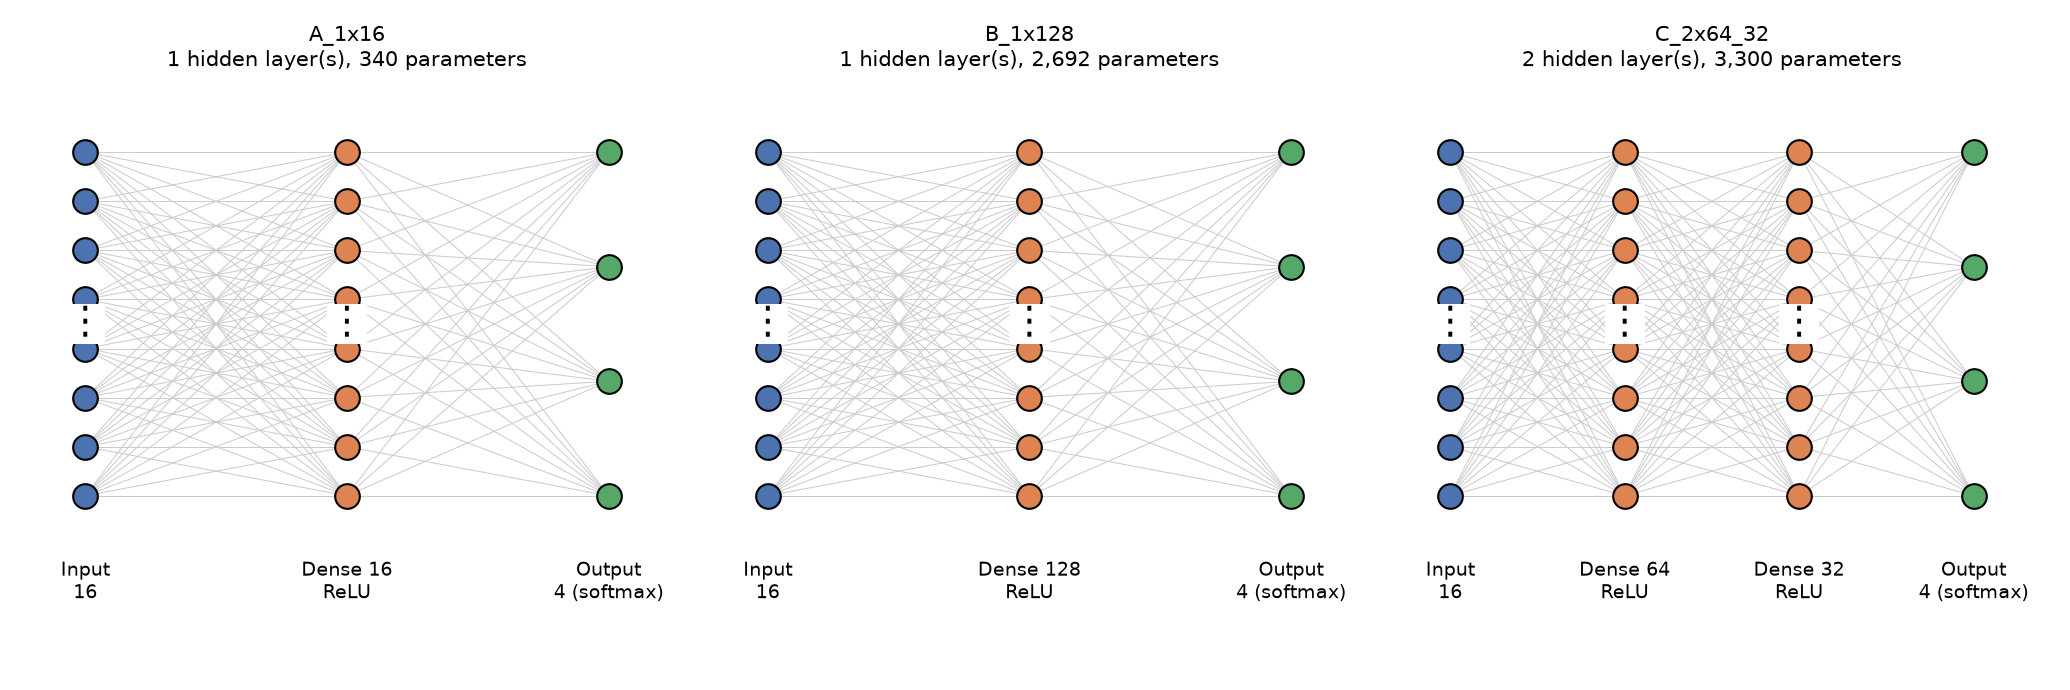

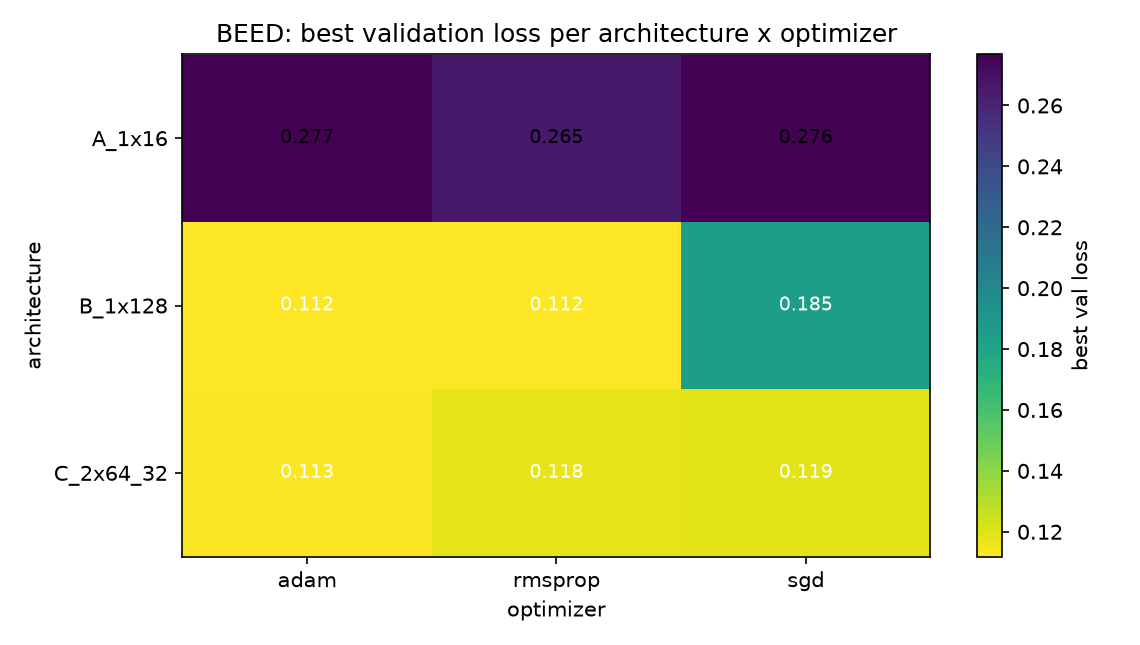

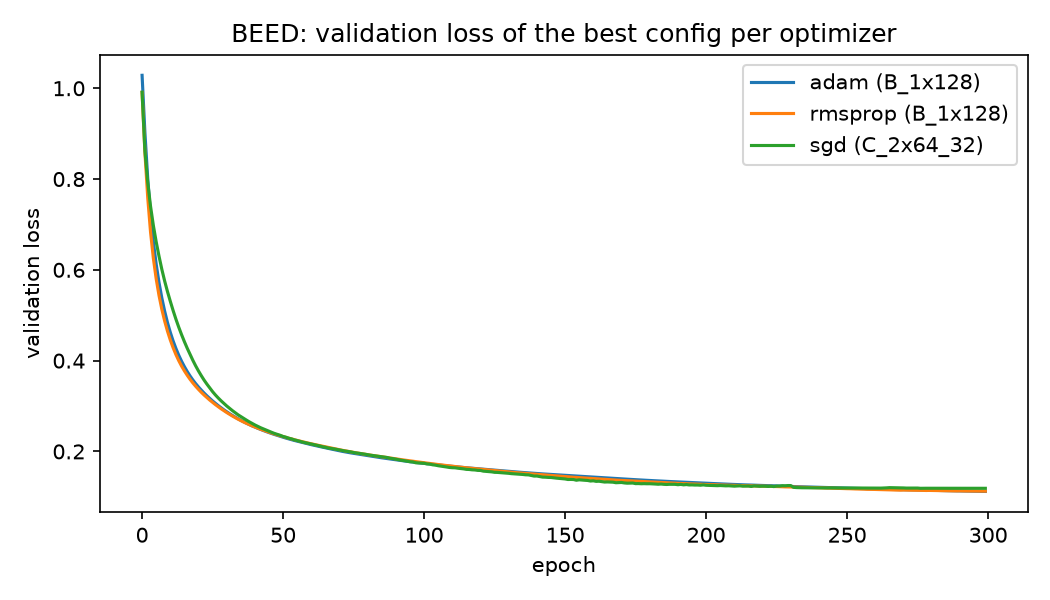

,architecture,optimizer,dropout,l2,val_loss,epochs,n_params
0,B_1x128,adam,0.0,0.0,0.1119,300,2692
1,B_1x128,rmsprop,0.0,0.0,0.1123,299,2692
2,C_2x64_32,adam,0.0,0.0,0.1131,147,3300
3,C_2x64_32,rmsprop,0.0,0.0,0.1182,210,3300
4,C_2x64_32,sgd,0.0,0.0,0.1187,284,3300
5,C_2x64_32,adam,0.2,0.0,0.1448,172,3300
6,B_1x128,adam,0.2,0.0,0.1462,268,2692
7,C_2x64_32,rmsprop,0.2,0.0,0.1496,175,3300
8,B_1x128,rmsprop,0.2,0.0,0.1593,233,2692
9,C_2x64_32,sgd,0.2,0.0,0.1681,223,3300


In [9]:
show_images(cfg.out_dir, ["architectures.png", "grid_heatmap.png", "optimizer_curves.png"])
pd.read_csv(Path(cfg.out_dir) / "grid_search.csv").round(4)

In [10]:
rows = {"MLP superficial (media 5 semillas)": {k: v["mean"] for k, v in clf["test_mlp"].items()}}
rows.update(clf["baselines"])
pd.DataFrame(rows).T.round(4)

,accuracy,macro_f1,roc_auc_ovr
MLP superficial (media 5 semillas),0.9568,0.9569,0.9965
majority_class,0.2500,0.1000,0.5000
logistic_regression,0.4650,0.4678,0.6590
random_forest,0.9608,0.9610,0.9972


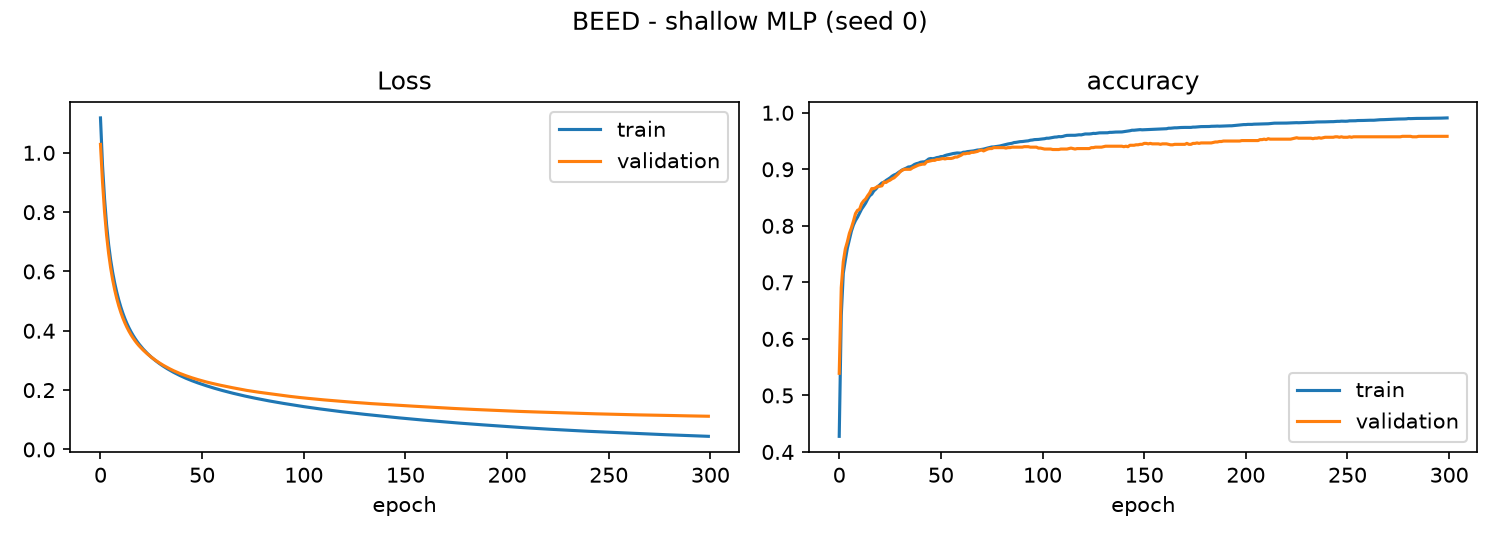

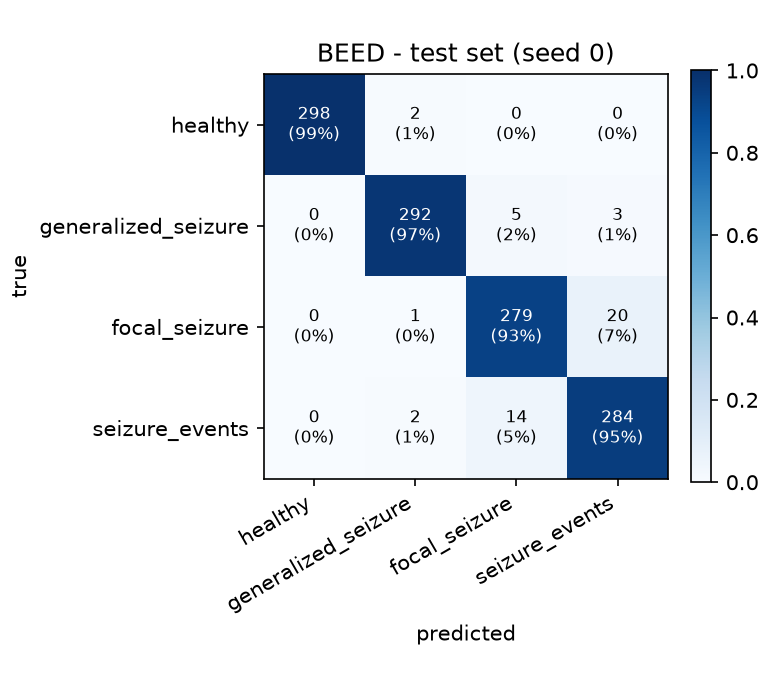

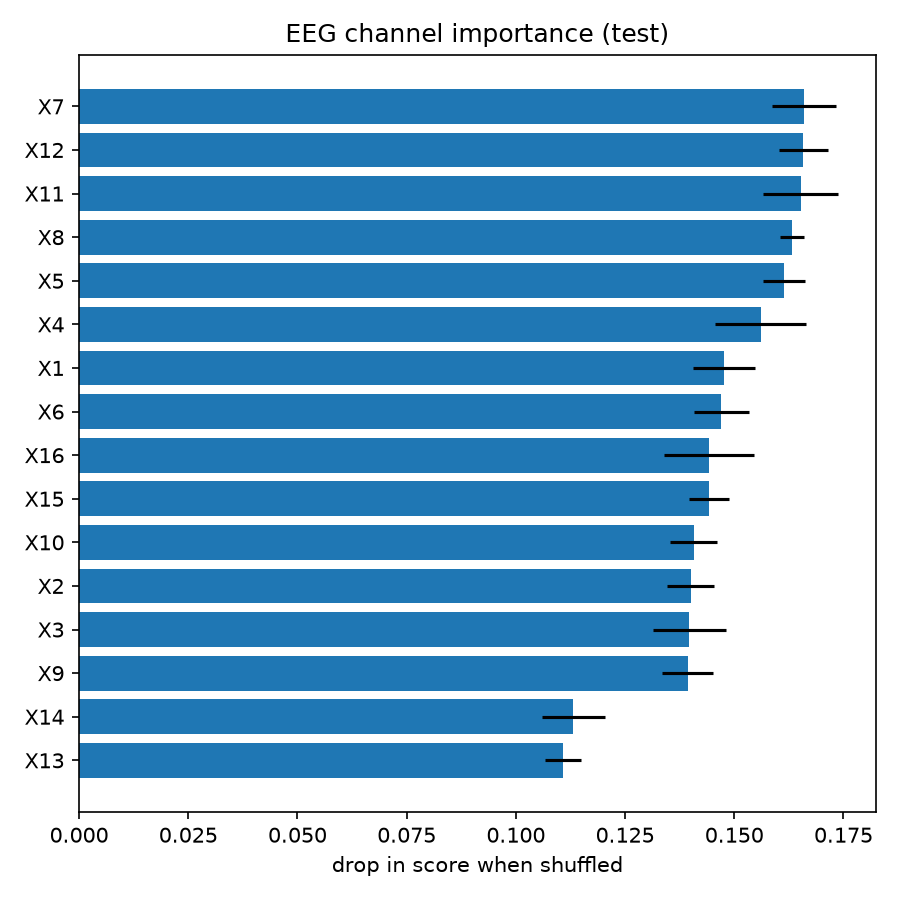

,precision,recall,f1-score,support
healthy,1.000,0.993,0.997,300.0
generalized_seizure,0.983,0.973,0.978,300.0
focal_seizure,0.936,0.930,0.933,300.0
seizure_events,0.925,0.947,0.936,300.0


In [11]:
show_images(cfg.out_dir, ["learning_curves.png", "confusion_matrix.png", "channel_importance.png"])
pd.DataFrame(clf["per_class_seed0"]).T[["precision", "recall", "f1-score", "support"]].round(3)

### Interpretación (clasificación)

- **Rendimiento.** El MLP superficial alcanza **95,7 % ± 0,3 %** de exactitud (macro-F1 0,957; AUC OvR 0,9965) en
  el conjunto de prueba, evaluado una sola vez y promediado sobre 5 semillas. Frente a la clase mayoritaria
  (25 %) y la regresión logística (46,5 %) la mejora es enorme: el problema es **no lineal**.
- **Honestidad frente al baseline.** El random forest obtiene 96,1 %, es decir, **ligeramente mejor** que el MLP
  (la diferencia, 0,4 puntos, es comparable a la desviación entre semillas). No se afirma que la red gane;
  se afirma que es competitiva con un modelo de árboles sin ajuste fino.
- **Arquitecturas.** `A_1x16` queda claramente atrás (pérdida de validación ≈ 0,27): subajusta. `B_1x128` y
  `C_2x64_32` rinden igual (≈ 0,11–0,12): con 2 capas no se gana nada frente a 1 capa ancha.
- **Optimizadores.** Adam y RMSprop convergen igual de rápido; SGD con momentum es más lento y solo alcanza a los
  demás con la arquitectura de 2 capas (0,119 frente a 0,185 en `B_1x128`).
- **Curvas de aprendizaje.** La pérdida de validación seguía bajando al llegar a las 300 épocas, así que
  `EarlyStopping` no llegó a activarse: el límite de épocas, y no el sobreajuste, fue lo que detuvo el
  entrenamiento. Hay una brecha train/validación creciente (exactitud 0,99 vs 0,96), señal de sobreajuste leve.
- **Errores.** La clase `healthy` se separa casi perfecto (99 %). La confusión se concentra entre
  `focal_seizure` y `seizure_events` (7 % y 5 %), las dos clases más parecidas.
- **Canales.** La importancia por permutación es **muy plana** (todos los canales caen entre 0,11 y 0,17): la
  información está repartida entre los 16 canales; X13 y X14 son los menos informativos.

## 2. Regresión: CD4 a las 20 semanas en ACTG 175

Ensayo clínico de 2.139 adultos con VIH. **Objetivo:** `cd420` (CD4 a las ~20 semanas).
**Predictores:** solo información **basal** (edad, peso, Karnofsky, días de antirretrovirales
previos, CD4 y CD8 basales, antecedentes clínicos, brazo de tratamiento `trt` y estrato `strat`).

**Sin fuga del futuro:** `cid`, `time`, `offtrt` y `cd820` son resultados o se miden después
de iniciar el tratamiento, así que se **excluyen**; `pidnum` es un identificador y `treat` es
redundante con `trt`. **Ética:** raza, género, actividad sexual y uso de drogas IV se excluyen
del modelo por defecto.

Referencia clínica: la línea base **"sin cambio"** (`cd420 = cd40`). El MLP debe superarla.

### 2.1 Análisis exploratorio (EDA)

In [12]:
eda = run_eda_actg175(D.load_actg175_raw(ACTG_PATH), REPORTS / "actg175_eda")
print("Pacientes:", eda["n_patients"], "| valores faltantes:", eda["missing_values"])
print("Correlación cd40 vs cd420:", round(eda["corr_cd40_cd420"], 3))
pd.DataFrame(eda["change_by_arm"]).T.round(2)

Pacientes: 2139 | valores faltantes: {}
Correlación cd40 vs cd420: 0.584


,n,mean_change,ci95
ZDV,532,-17.065789,"[-25.962454, -8.169125]"
ZDV+ddI,522,54.448276,"[42.071211, 66.825341]"
ZDV+Zal,524,19.263359,"[9.64295, 28.883767]"
ddI,561,26.857398,"[17.379593, 36.335202]"


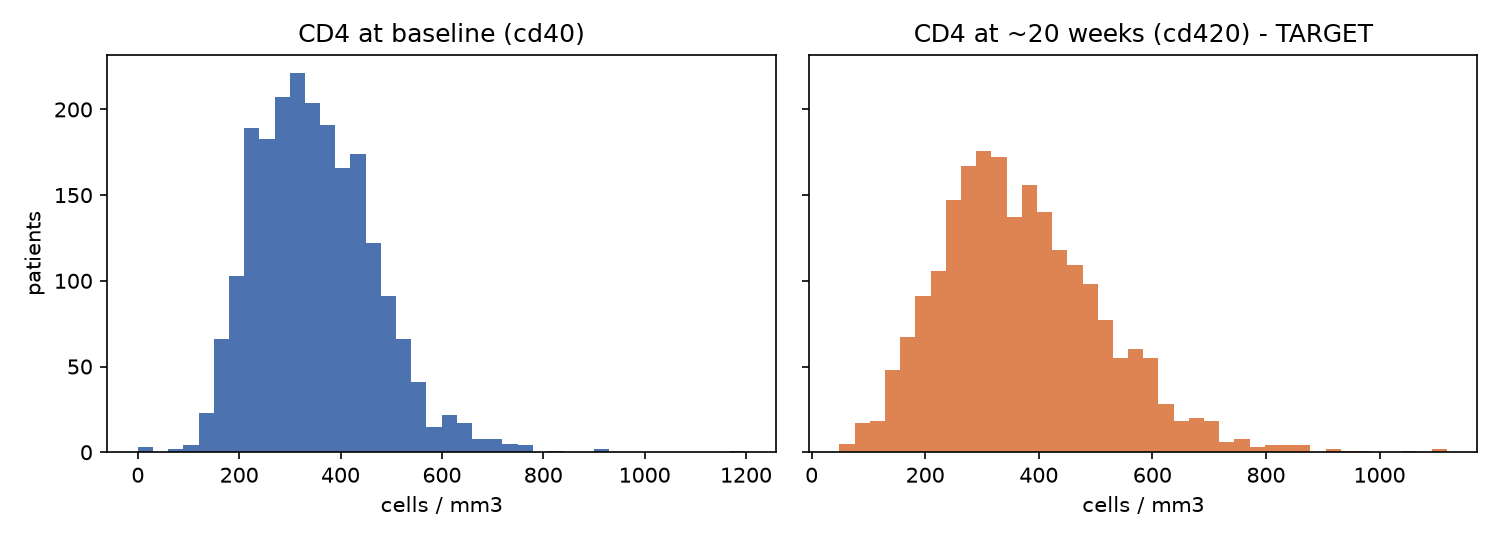

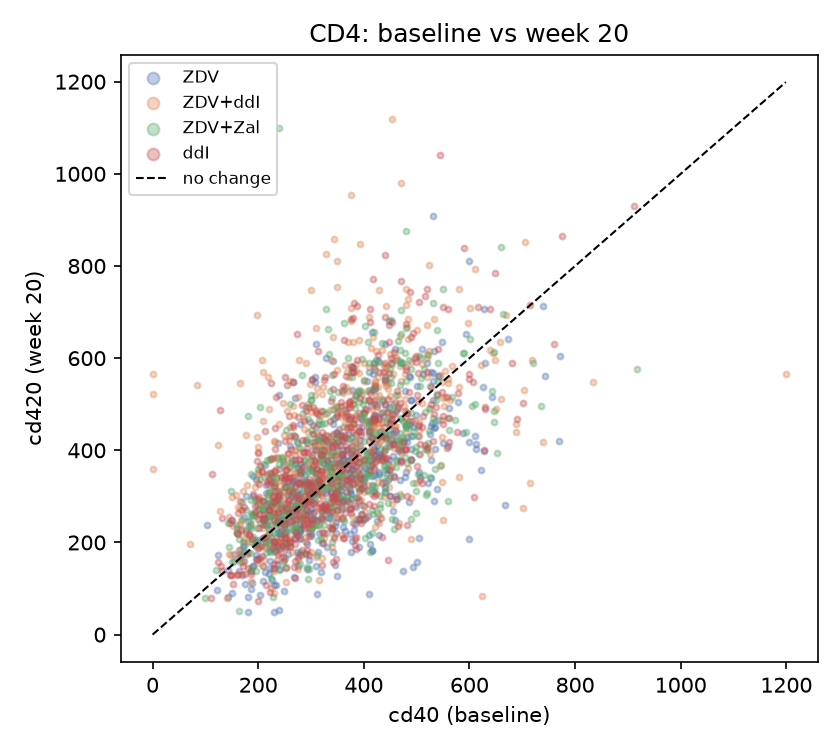

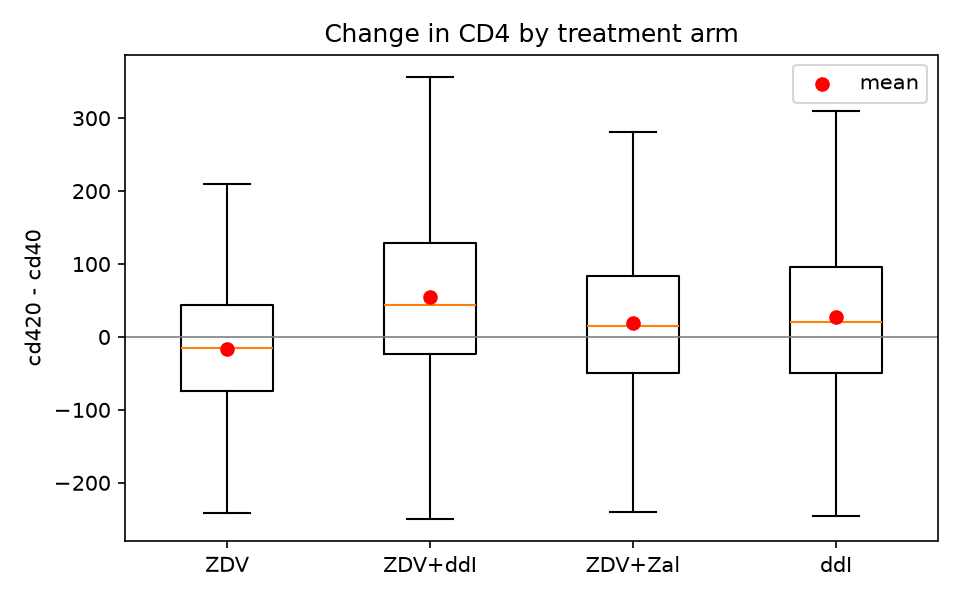

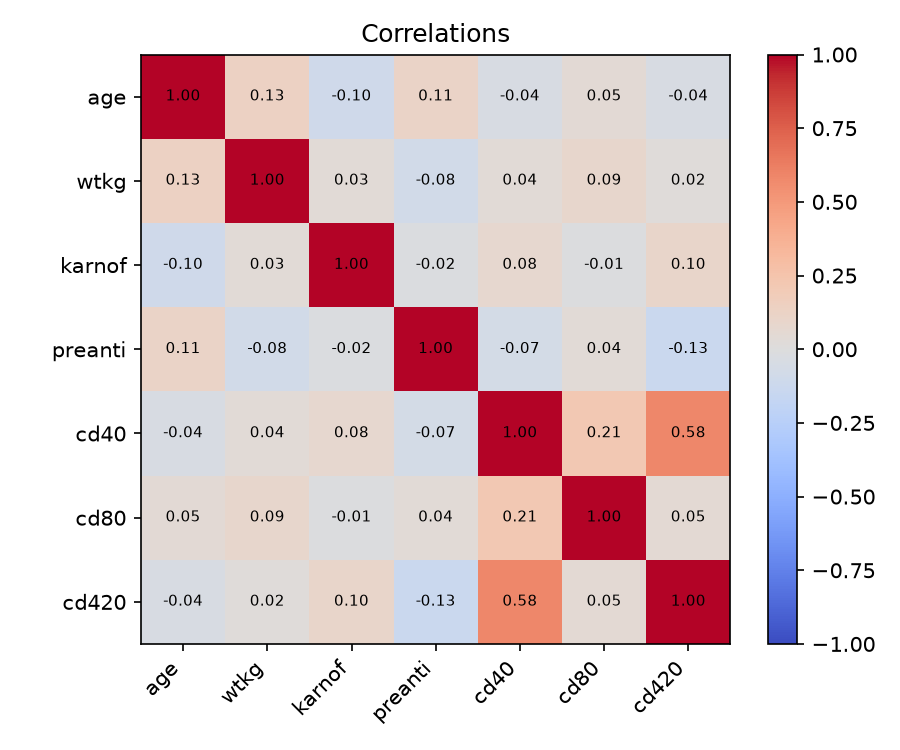

In [13]:
show_images(REPORTS / "actg175_eda", ["eda_target_distribution.png", "eda_cd40_vs_cd420.png",
                                       "eda_treatment_effect.png", "eda_correlations.png"])

### Hallazgos del EDA

- Hay 2.139 pacientes y **ningún valor faltante**; cada fila es un paciente distinto, por lo que una división
  aleatoria no filtra información entre conjuntos.
- La correlación entre el CD4 basal (`cd40`) y el de la semana 20 (`cd420`) es **0,584**: la mejor predicción
  ya está en el valor de partida y el modelo solo puede añadir lo que aportan tratamiento y covariables.
- **Efecto del tratamiento** (cambio medio de CD4, IC 95 %): ZDV solo −17 [−26, −8]; ZDV+ddI **+54** [+42, +67];
  ZDV+Zal +19 [+10, +29]; ddI solo +27 [+17, +36]. El intervalo de ZDV+ddI no se solapa con el de ZDV solo.
  Es una asociación descriptiva sobre un ensayo aleatorizado, no un análisis causal formal.

### 2.2 Entrenamiento y evaluación

### 2.2 Entrenamiento y evaluación

In [14]:
cfg_a = RunConfig(out_dir=str(REPORTS / "actg175_regression"), data_path=ACTG_PATH,
                  dataset="actg175")
reg = run_regression(cfg_a)

print("Tamaños:", reg["split_sizes"], "| split:", reg["split_mode"])
print("Mejores hiperparámetros:", reg["best_hyperparameters"], "| parámetros:", reg["n_parameters"])
rows = {"MLP superficial (media 5 semillas)": {k: v["mean"] for k, v in reg["test_mlp"].items()}}
rows.update(reg["baselines"])
pd.DataFrame(rows).T.round(3)

Tamaños: {'train': 1497, 'val': 321, 'test': 321} | split: random
Mejores hiperparámetros: {'optimizer': 'sgd', 'dropout': 0.2, 'l2': 0.0, 'hidden_layers': (128,)} | parámetros: 2689


,rmse,mae,r2
MLP superficial (media 5 semillas),113.027,86.782,0.361
mean_predictor,141.631,112.759,-0.003
ridge,111.610,84.555,0.377
random_forest,116.517,90.265,0.321
no_change (cd420 = cd40),124.434,92.832,0.226


### Arquitecturas y optimizadores (ACTG 175)

Se compararon **3 arquitecturas** (máx. 2 capas ocultas: `A_1x16`, `B_1x128`, `C_2x64_32`) y
**3 optimizadores** (Adam, SGD con momentum 0,9 y RMSprop), cada combinación con y sin dropout,
y se eligió por la **pérdida de validación**. Abajo: diagramas de las arquitecturas, mapa de calor
arquitectura × optimizador, curvas del mejor modelo de cada optimizador y tabla completa.

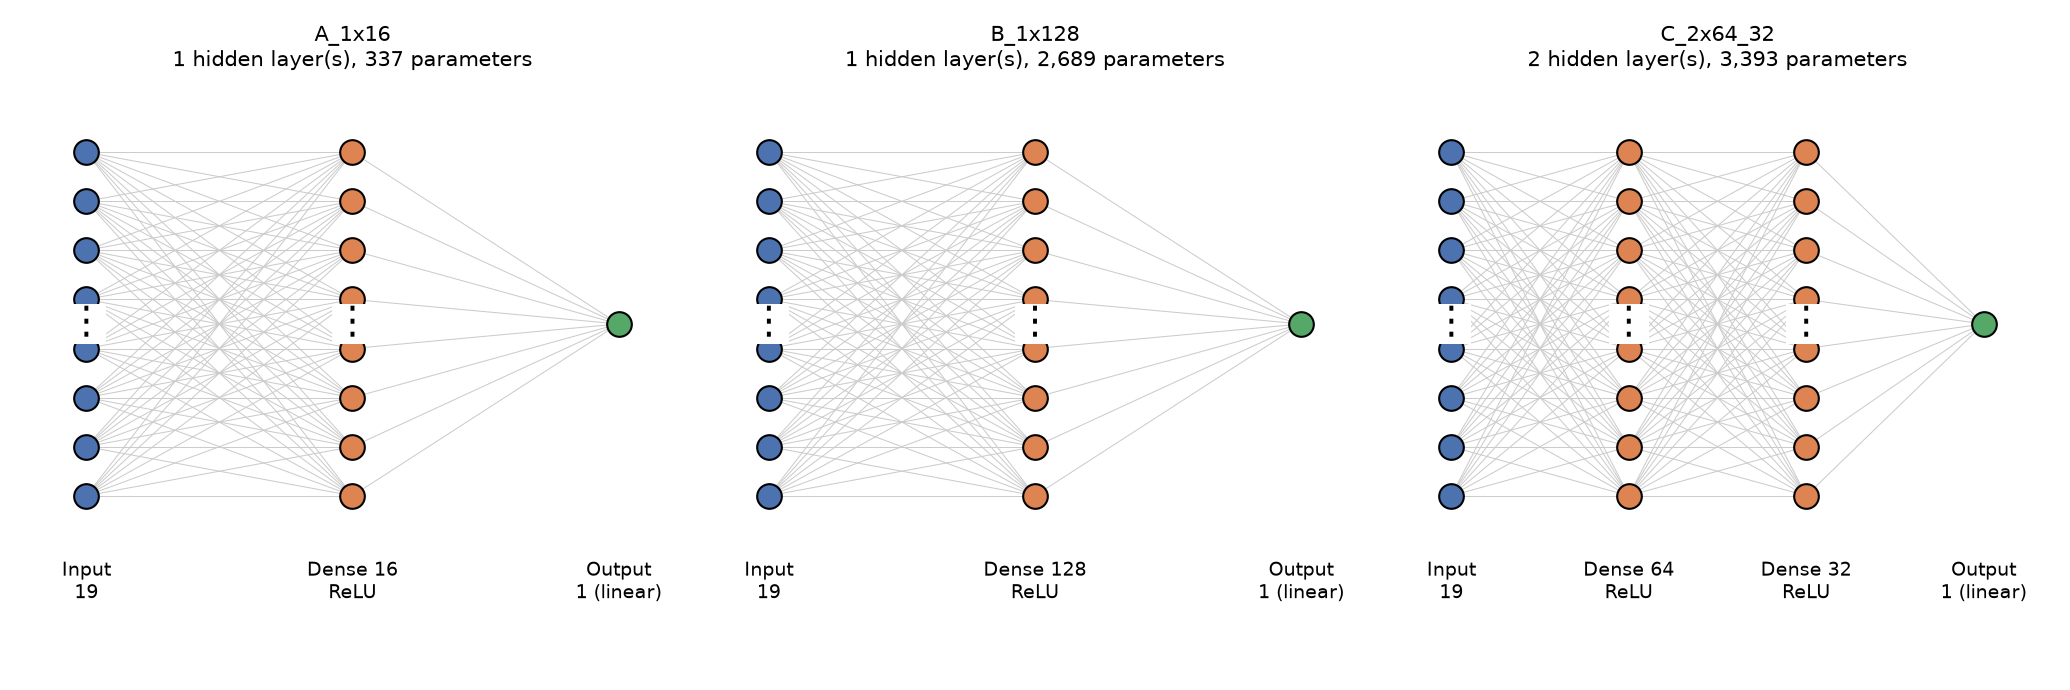

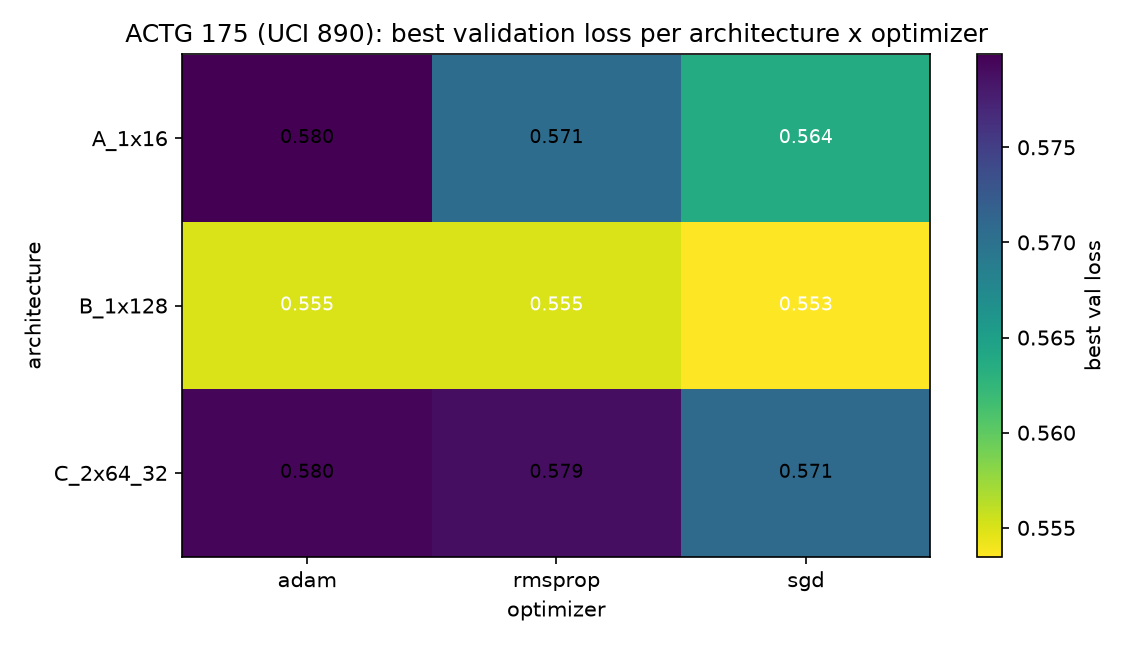

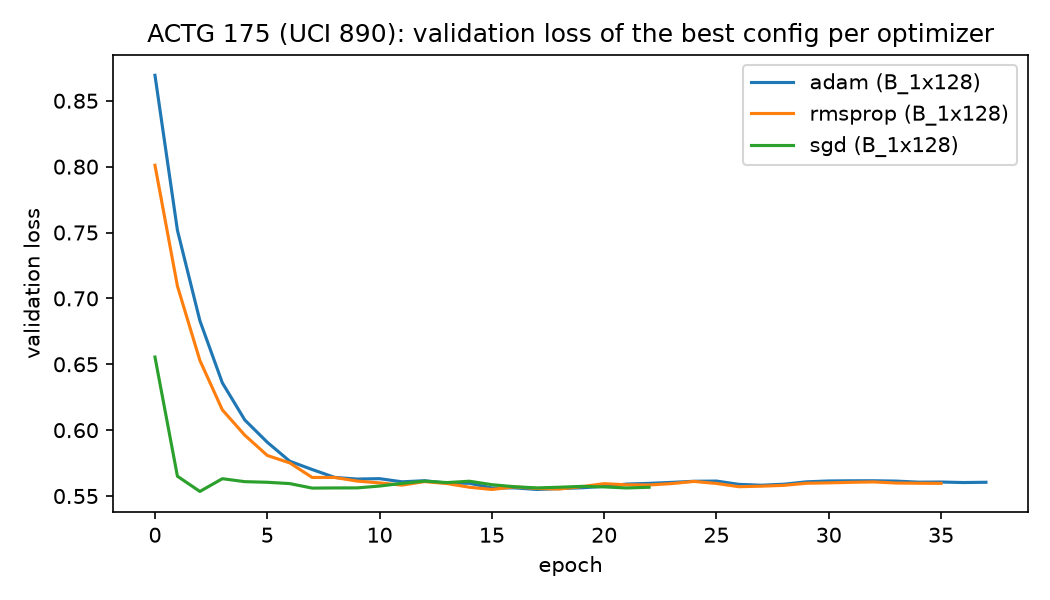

,architecture,optimizer,dropout,l2,val_loss,epochs,n_params
0,B_1x128,sgd,0.2,0.0,0.5535,3,2689
1,B_1x128,adam,0.2,0.0,0.5550,18,2689
2,B_1x128,rmsprop,0.2,0.0,0.5550,16,2689
3,A_1x16,sgd,0.2,0.0,0.5636,17,337
4,A_1x16,rmsprop,0.2,0.0,0.5706,61,337
5,C_2x64_32,sgd,0.2,0.0,0.5707,19,3393
6,B_1x128,sgd,0.0,0.0,0.5750,13,2689
7,A_1x16,sgd,0.0,0.0,0.5762,26,337
8,B_1x128,rmsprop,0.0,0.0,0.5772,33,2689
9,A_1x16,rmsprop,0.0,0.0,0.5781,51,337


In [15]:
show_images(cfg_a.out_dir, ["architectures.png", "grid_heatmap.png", "optimizer_curves.png"])
pd.read_csv(Path(cfg_a.out_dir) / "grid_search.csv").round(4)

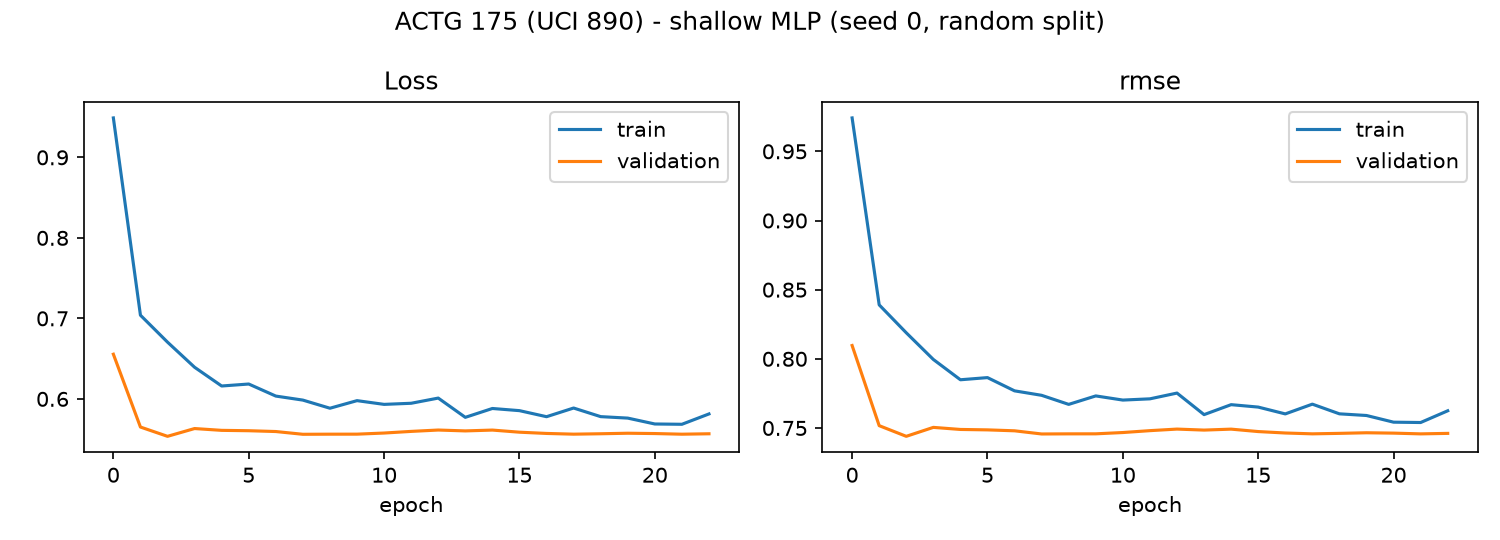

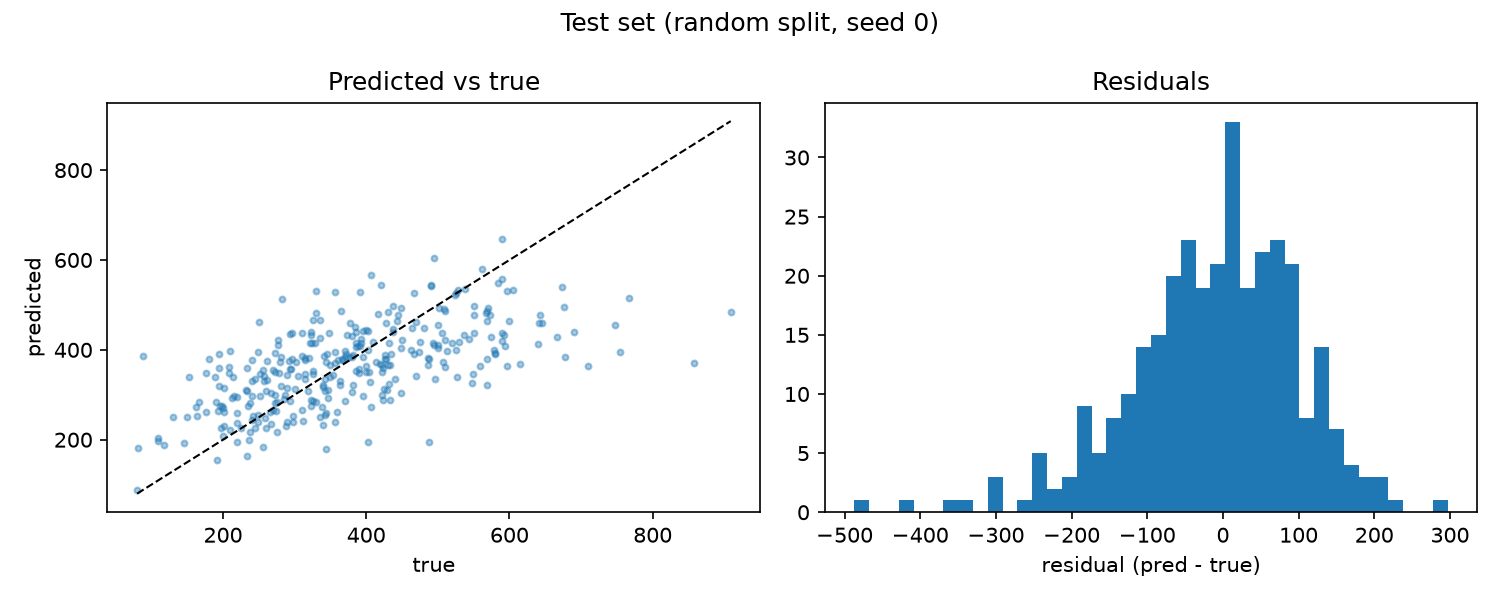

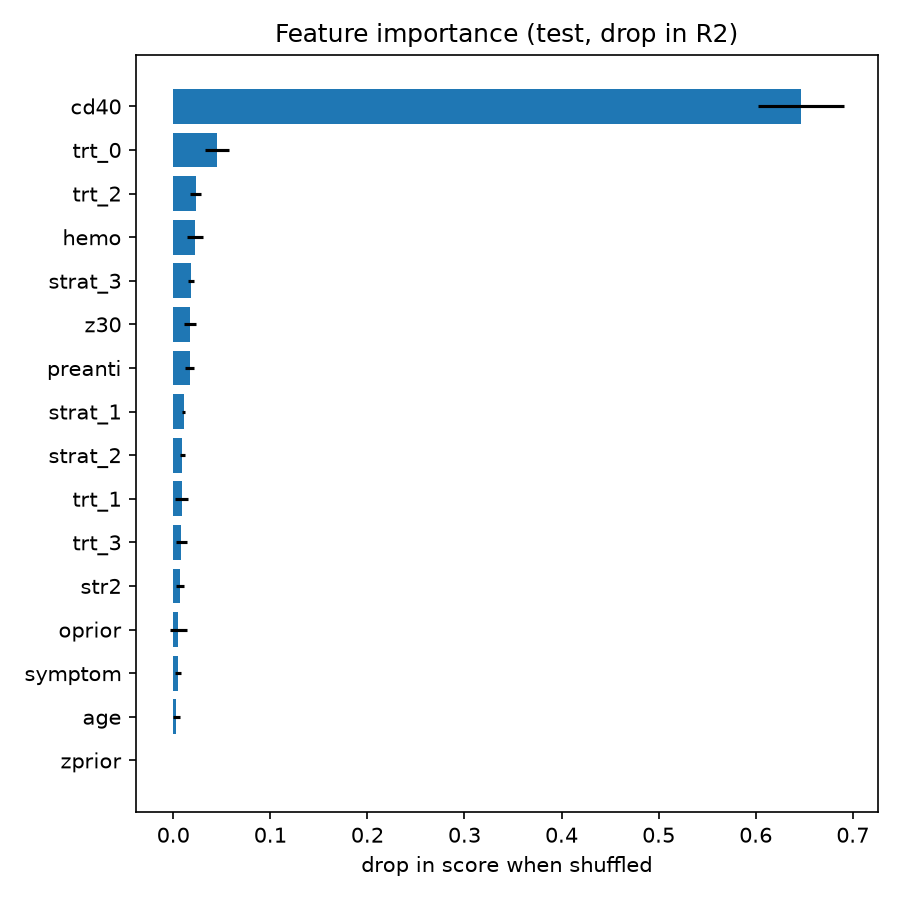

In [16]:
show_images(cfg_a.out_dir, ["learning_curves.png", "pred_vs_true.png", "feature_importance.png"])

### Interpretación (regresión)

- **Resultado.** MLP: RMSE 113,0, MAE 86,8, **R² 0,361** (media de 5 semillas). Supera con claridad al predictor
  de la media (R² ≈ 0) y a "sin cambio" `cd420 = cd40` (R² 0,226), pero **no supera a Ridge** (R² 0,377, RMSE 111,6);
  el random forest queda en 0,321. Es decir, la relación es casi lineal y una red no aporta ventaja aquí.
- **Variable dominante.** `cd40` explica casi todo: al barajarla el R² cae ≈ 0,65. Le siguen el brazo de
  tratamiento (`trt_0`, ZDV solo, ≈ 0,05), hemofilia, `z30` y `preanti`, todas con efectos pequeños.
- **Diagnóstico visual.** Los puntos predichos vs reales se comprimen hacia la media (se subestiman los CD4
  altos) y los residuos son aproximadamente simétricos, con colas de ±300.
- **Selección de hiperparámetros.** Las 18 configuraciones difieren menos de 0,05 en pérdida de validación;
  la elegida (SGD, 128 neuronas, dropout 0,2) no es significativamente mejor que las demás. Con 321 pacientes de
  validación, esa diferencia es ruido y no debe sobreinterpretarse.
- **Variables sensibles** (`race`, `gender`, `homo`, `drugs`) se excluyeron por defecto; el flag
  `--include-sensitive` permite medir su efecto (no se ejecutó en esta corrida).

## 3. Conclusiones

1. Un MLP superficial resuelve bien la clasificación de EEG (95,7 %), con 1 capa de 128 neuronas y Adam;
   un random forest sin ajuste lo iguala (96,1 %).
2. En regresión (ACTG 175) el MLP (R² 0,36) supera a los baselines ingenuos pero no a Ridge: **la complejidad
   no siempre paga**.
3. Adam y RMSprop convergen más rápido que SGD; 2 capas no mejoran frente a 1 capa ancha.
4. La metodología (partición sin fuga, escalador solo con entrenamiento, prueba evaluada una vez, semillas,
   baselines) importa tanto como la arquitectura: una cifra defendible vale más que una alta.

**Siguientes pasos.** Aumentar épocas o ancho (256 neuronas) en BEED, validación cruzada, y comparar con
`--include-sensitive`.

**Limitaciones.** BEED no trae identificador de sujeto (no se puede dividir por persona) y su
descripción es inconsistente; ACTG 175 es un ensayo histórico (1996) con variables sensibles;
las diferencias entre hiperparámetros en ACTG están dentro del ruido. Trabajo educativo, no un dispositivo médico.